In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

In [2]:
df = pd.read_parquet('../data/processed/test_predictions.parquet')

assert len(df) == 1329
assert len(df[df['y_true'] == 1]) == 47
assert df['b_pred'].isna().sum() == 0
assert (df['b_pred'].min() > 0 and df['b_pred'].max() < 1)

In [3]:
def get_frac_values(data, fracs):
    lst = []
    data = data.sort_values(by='b_pred', ascending=False)
    for frac in fracs:
        n_screen = round(frac * len(data))
        rows = data.head(n_screen)
        found = rows['y_true'].sum()
        sensitivity = found / len(data[data['y_true'] == 1])
        ppv = found / n_screen
        nns = n_screen / found
        lst.append({'n_screen': n_screen, 'found': found, 'sensitivity': sensitivity, 'ppv': ppv,'nns':nns})

    return pd.DataFrame(lst, index=fracs)

fractions = [0.1,0.2,0.3]
get_frac_values(df, fractions)

,n_screen,found,sensitivity,ppv,nns
0.1,133,18,0.382979,0.135338,7.388889
0.2,266,28,0.595745,0.105263,9.500000
0.3,399,38,0.808511,0.095238,10.500000


In [4]:
single_choice = [1]

df['age_points'] = pd.cut(
    df['age_at_screening'],
    bins=[0,40,50,60,np.inf],
    labels=[0,1,2,3],
    right=False
).astype('int')

df['male_points'] = np.select(
    [df['sex'] == 'male'],
    single_choice,
    default=0
)

df['family_points'] = np.select(
    [df['family_history_diabetes'] == True],
    single_choice,
    default=0
)

df['bp_points'] = np.select(
    [df['told_high_bp'] == True],
    single_choice,
    default=0
)

df['inactive_points'] = np.select(
    [df['active_leisure'] == 0],
    single_choice,
    default=0
)
df['bmi_points'] = pd.cut(
    df['bmi'],
    bins=[0,25,30,40,np.inf],
    labels=[0,1,2,3],
    right=False
).fillna(0).astype('int')

df['ada_score'] = (
    df['age_points'] + df['male_points'] + df['family_points'] + df['bp_points'] + df['inactive_points'] + df['bmi_points']
)

assert df['ada_score'].between(0, 10).all()

display(df[['ada_score']].sort_values(by='ada_score', ascending=False))

,ada_score
756,10
1076,10
1025,9
715,9
188,9
...,...
1056,0
81,0
1303,0
435,0


In [5]:
ada_df = df[df['ada_score']>= 5]

n_flagged = len(ada_df)
found = ada_df['y_true'].sum()
sensitivity = found / len(df[df['y_true'] == 1])
ppv = found / n_flagged
nns = n_flagged / found

auc_ada = roc_auc_score(df['y_true'], df['ada_score'])
auc_model = roc_auc_score(df['y_true'], df['b_pred'])

ada_row = {
    'n_screen': n_flagged,
    'found': found,
    'sensitivity': sensitivity,
    'ppv': ppv,
    'nns': nns,
    'roc_auc': auc_ada
}

model_row = get_frac_values(df, [n_flagged / len(df)]).iloc[0].to_dict()
model_row['roc_auc'] = auc_model

comparison = pd.DataFrame([ada_row, model_row], index=['ADA score >= 5', 'LogReg B'])
display(comparison)

,n_screen,found,sensitivity,ppv,nns,roc_auc
ADA score >= 5,630.0,40.0,0.851064,0.063492,15.75,0.763443
LogReg B,630.0,45.0,0.957447,0.071429,14.00,0.828377


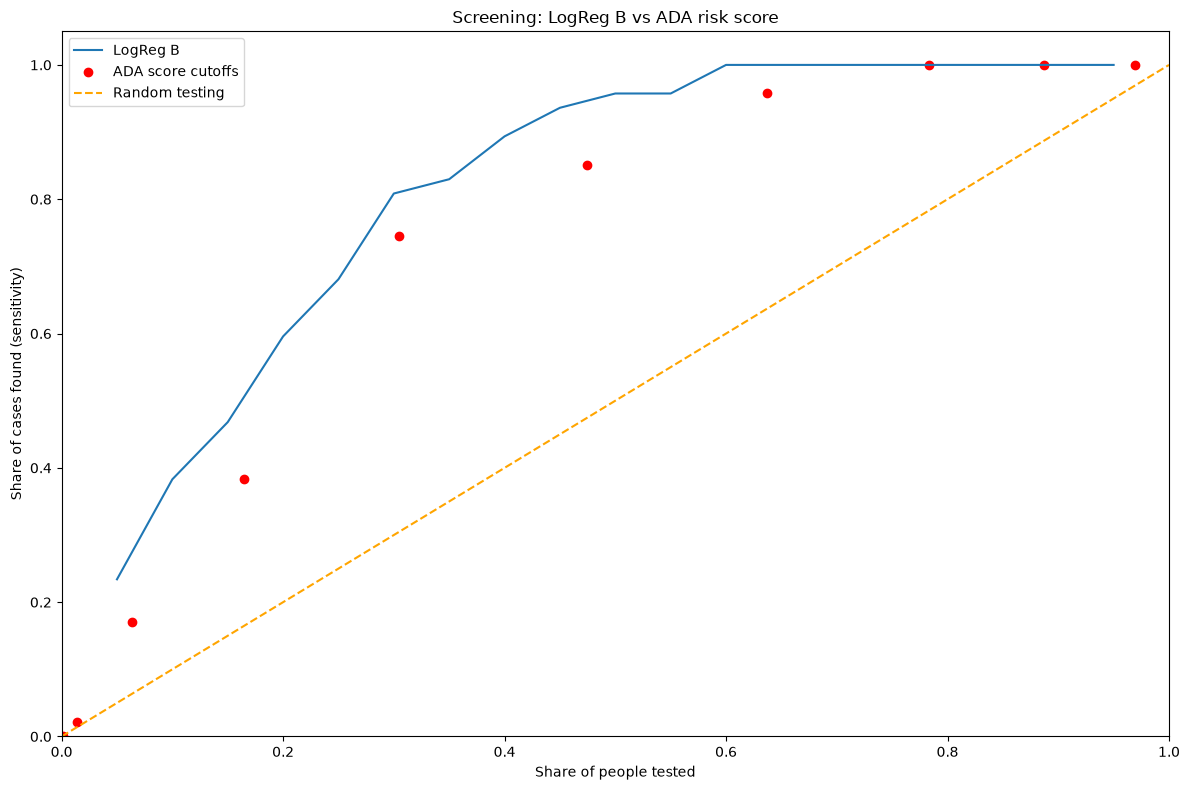

In [6]:
fig, ax = plt.subplots(figsize=(12,8))

plot_df = get_frac_values(df, np.arange(0.05, 1.0, step=0.05))

ada_frac, ada_sens = [], []

for k in range(1,11): 
    flagged = df[df['ada_score'] >= k]
    ada_frac.append(len(flagged) / len(df))
    ada_sens.append(flagged['y_true'].sum() / df['y_true'].sum())


ax.plot(plot_df.index, plot_df['sensitivity'], label='LogReg B')
ax.scatter(ada_frac, ada_sens, color='red', label='ADA score cutoffs')

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.plot([0,1], [0,1], color='orange', ls='--', label='Random testing')
ax.set_ylabel('Share of cases found (sensitivity)')
ax.set_xlabel('Share of people tested')
ax.set_title('Screening: LogReg B vs ADA risk score')
ax.legend()

plt.tight_layout()
fig.savefig('../reports/figures/screening_curve.png', bbox_inches='tight')
plt.show()

## Summary

- **Screening with LogReg B:** testing the top 30% by risk finds 81% of undiagnosed cases (about 10 tests per case found, vs about 28 with random testing).
- **ADA risk score (≥ 5)** flags 47% of adults and finds 85% of cases.
- **Same number of tests (630):** the model finds 45 of 47 cases, the ADA score 40. ROC-AUC 0.83 vs 0.76.
- **At every testing level** the model finds more cases than the ADA score.
- **Caveat:** only 47 cases in the test set; the gap of 5 cases is small. Gestational diabetes (one ADA point) was not available.